In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("../data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

# 1. Display the number of rows and columns
# This helps us understand the overall size of the dataset
print("Dataset shape:", df.shape)

# 2. Display all column names
# These columns describe transactions, products, customers, and sales
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check the data types of each column
# For example, dates should eventually be datetime values
print("\nData types:")
print(df.dtypes)

# 4. Count missing values in every column
# Missing values may affect calculations and analysis
print("\nMissing values:")
print(df.isnull().sum())

# 5. Display descriptive statistics for all columns
# This helps us identify unusual values and understand the data
print("\nStatistical summary:")
display(df.describe(include="all").T)


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

# Count rows that are exact duplicates
# Duplicate records can distort sales and transaction analysis
print("Exact duplicate rows:", df.duplicated().sum())

# Show a sample of transactions with zero or negative quantities
# These may represent returns or data issues, so inspect them before cleaning
print("\nNon-positive quantities:")
display(df[df["Quantity"] <= 0].head(10))

# Show transactions with zero or negative unit prices
# These records need investigation before revenue calculations
print("\nNon-positive unit prices:")
display(df[df["UnitPrice"] <= 0].head(10))

# Display the earliest and latest transaction dates
# This checks the time period covered by the dataset
print("\nTransaction date range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())


Exact duplicate rows: 5268

Non-positive quantities:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



Non-positive unit prices:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Transaction date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [5]:

# ==========================================
# STEP 6: DATA CLEANING AND PREPARATION
# ==========================================

# Create a copy so that the original dataset remains unchanged
clean_df = df.copy()

# 1. Remove exact duplicate rows
# Duplicates can inflate sales and transaction counts
clean_df = clean_df.drop_duplicates()

print("Rows after removing duplicates:", clean_df.shape[0])


# 2. Convert InvoiceDate to datetime format
# This allows us to group transactions by day, month, or year
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

# Remove records where the invoice date could not be converted
clean_df = clean_df.dropna(subset=["InvoiceDate"])


# 3. Identify cancelled invoices
# In this dataset, invoice numbers beginning with C commonly indicate cancellations
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype("string")

cancelled_mask = clean_df["InvoiceNo"].str.startswith(
    "C", na=False
)

# Count cancellation records before filtering
print("Cancellation records:", cancelled_mask.sum())


# 4. Identify rows with missing customer IDs
# We will measure missing IDs before deciding how to handle them
print(
    "Rows with missing CustomerID:",
    clean_df["CustomerID"].isna().sum()
)


# 5. Create a revenue column
# Revenue is calculated as quantity multiplied by unit price
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Show the first few records to verify the new column
display(clean_df.head())


# 6. Review the cleaning results
# These checks help us understand the dataset before filtering further
print("Current dataset shape:", clean_df.shape)

print(
    "Rows with zero or negative quantity:",
    (clean_df["Quantity"] <= 0).sum()
)

print(
    "Rows with zero or negative unit price:",
    (clean_df["UnitPrice"] <= 0).sum()
)

print(
    "Total revenue before business-rule filtering:",
    round(clean_df["Revenue"].sum(), 2)
)


Rows after removing duplicates: 536641
Cancellation records: 9251
Rows with missing CustomerID: 135037


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Current dataset shape: (536641, 9)
Rows with zero or negative quantity: 10587
Rows with zero or negative unit price: 2512
Total revenue before business-rule filtering: 9726006.95


In [6]:

# ==========================================
# STEP 7: FILTER VALID SALES RECORDS
# ==========================================

# Start with a copy of the dataset after basic cleaning
sales_df = clean_df.copy()

# Remove cancelled invoices from the sales analysis
# Keep the cancellation records in clean_df for reference
sales_df = sales_df[
    ~sales_df["InvoiceNo"].str.startswith("C", na=False)
].copy()

# Keep only transactions with positive quantities and prices
# This creates a consistent dataset for analysing positive sales
sales_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

# Recalculate revenue after applying the sales filters
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# Display the number of records removed by the sales filters
print("Rows in original dataset:", len(df))
print("Rows in sales dataset:", len(sales_df))

# Calculate total sales revenue
print(
    "Total sales revenue:",
    round(sales_df["Revenue"].sum(), 2)
)

# Check whether any invalid sales records remain
print(
    "Non-positive quantities remaining:",
    (sales_df["Quantity"] <= 0).sum()
)

print(
    "Non-positive prices remaining:",
    (sales_df["UnitPrice"] <= 0).sum()
)

# Display a sample of the prepared sales dataset
display(sales_df.head())


Rows in original dataset: 541909
Rows in sales dataset: 524878
Total sales revenue: 10642110.8
Non-positive quantities remaining: 0
Non-positive prices remaining: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [8]:

# STEP 8: EXPORT THE CLEANED DATASET

# Import Path to work with folders and file paths
from pathlib import Path

# Create the outputs folder in the main project directory
# This works even if the folder does not already exist
output_dir = Path.cwd().parent / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Define the complete path for the exported CSV file
output_file = output_dir / "retail_sales_cleaned.csv"

# Export the cleaned sales dataset without the DataFrame index
sales_df.to_csv(output_file, index=False)

# Confirm that the file was saved successfully
print("Cleaned sales dataset exported successfully!")
print("Saved location:", output_file.resolve())
print("File exists:", output_file.exists())


Cleaned sales dataset exported successfully!
Saved location: C:\Users\Admin\Desktop\Retail-Business-Analytics\outputs\retail_sales_cleaned.csv
File exists: True


In [9]:
# Display the notebook's current working directory
from pathlib import Path
print("Current directory:", Path.cwd())

Current directory: c:\Users\Admin\Desktop\Retail-Business-Analytics\notebooks


Top 10 Products by Revenue:


,StockCode,Description,TotalRevenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


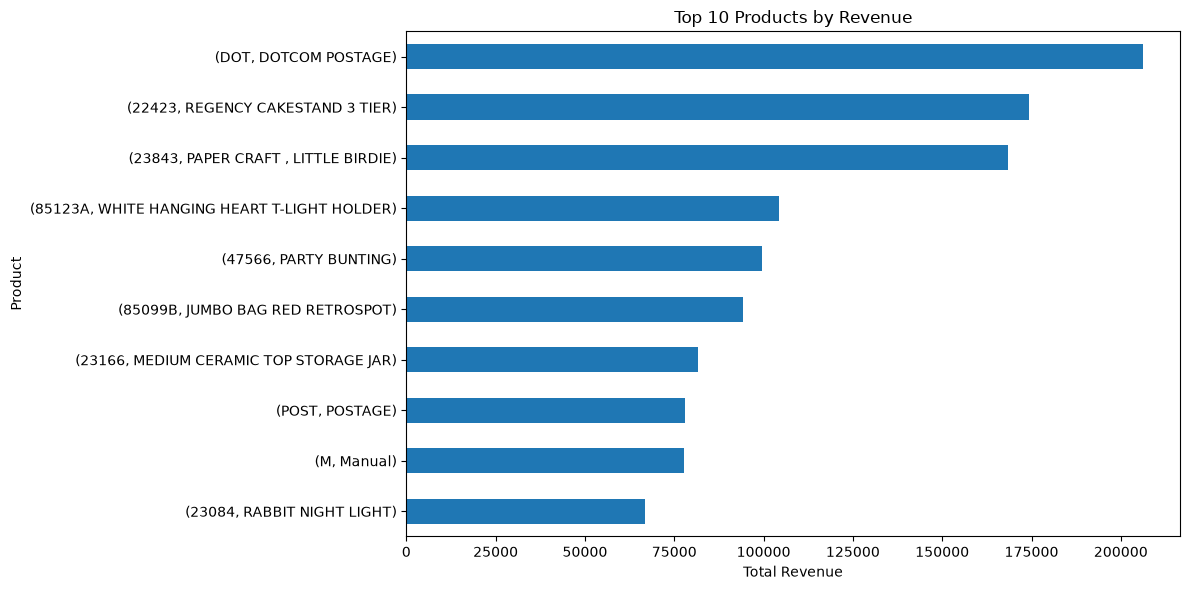

Top 10 products exported successfully!


In [10]:

# ==========================================
# STEP 10: TOP 10 PRODUCTS BY REVENUE
# ==========================================

# Group sales by product code and description
# Add the revenue from all transactions for each product
product_revenue = (
    sales_df.groupby(
        ["StockCode", "Description"],
        dropna=False
    )["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 products that generated the most revenue
top_10_products = product_revenue.head(10)

# Convert the results into a readable table
top_10_table = top_10_products.reset_index(
    name="TotalRevenue"
)

# Display the top 10 products
print("Top 10 Products by Revenue:")
display(top_10_table)

# Create a horizontal bar chart to compare products
plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind="barh")

# Add a descriptive title and axis labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

# Export the top 10 products to a CSV file
top_10_table.to_csv(
    output_dir / "top_10_products.csv",
    index=False
)

print("Top 10 products exported successfully!")


Top 10 Countries by Revenue:


,Country,TotalRevenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


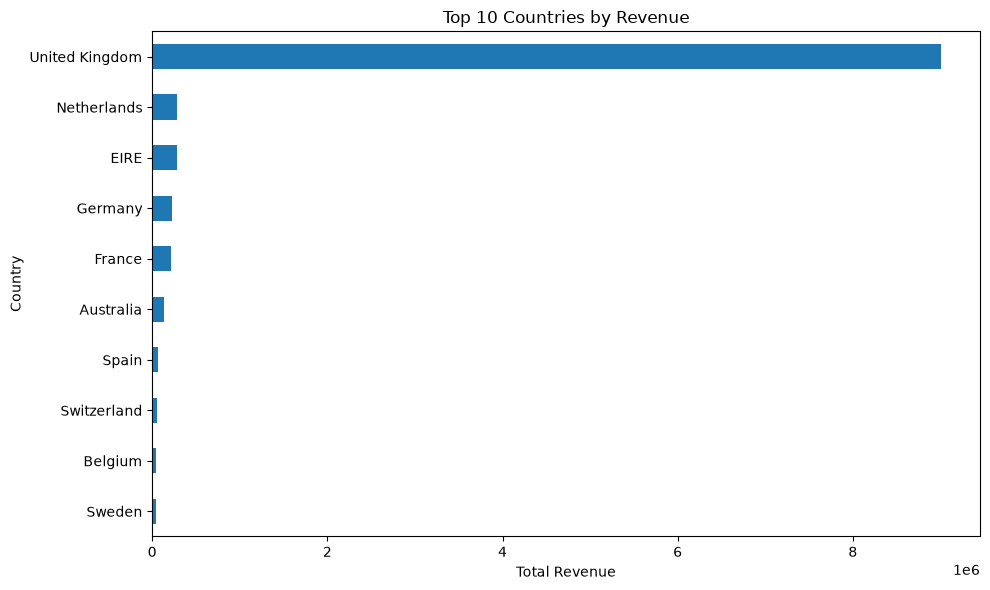

Country revenue summary exported successfully!


In [11]:

# ==========================================
# STEP 11: COUNTRY-LEVEL REVENUE ANALYSIS
# ==========================================

# Group all transactions by country
# Calculate the total revenue generated in each country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 countries with the highest revenue
top_10_countries = country_revenue.head(10)

# Convert the results into a readable table
country_table = top_10_countries.reset_index(
    name="TotalRevenue"
)

# Display the country rankings
print("Top 10 Countries by Revenue:")
display(country_table)

# Create a horizontal bar chart for comparison
plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(kind="barh")

# Add chart title and labels
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

# Export the complete country revenue summary
country_revenue.rename("Revenue").reset_index().to_csv(
    output_dir / "country_revenue.csv",
    index=False
)

print("Country revenue summary exported successfully!")


In [13]:

# ==========================================
# STEP 12: CALCULATE AND EXPORT MONTHLY REVENUE
# ==========================================

# Import Path in case it has not been imported already
from pathlib import Path

# Create the outputs folder if it does not exist
output_dir = Path.cwd().parent / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Make a copy of the sales dataset for monthly analysis
monthly_df = sales_df.copy()

# Extract the calendar month from each invoice date
monthly_df["Month"] = (
    pd.to_datetime(monthly_df["InvoiceDate"]).dt.to_period("M")
)

# Group transactions by month and calculate total revenue
monthly_revenue = (
    monthly_df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

# Display the monthly revenue results
print("Monthly Revenue:")
display(monthly_revenue.rename("Revenue").reset_index())

# Export monthly revenue to a CSV file
monthly_revenue.rename("Revenue").reset_index().to_csv(
    output_dir / "monthly_revenue.csv",
    index=False
)

# Confirm that the export was successful
print("Monthly revenue summary exported successfully!")
print("File exists:", (output_dir / "monthly_revenue.csv").exists())


Monthly Revenue:


,Month,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


Monthly revenue summary exported successfully!
File exists: True


Top 10 Products by Revenue:


,StockCode,Description,TotalRevenue
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174156.54
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24
4,47566,PARTY BUNTING,99445.23
5,85099B,JUMBO BAG RED RETROSPOT,94159.81
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POST,POSTAGE,78101.88
8,M,Manual,77750.27
9,23084,RABBIT NIGHT LIGHT,66870.03


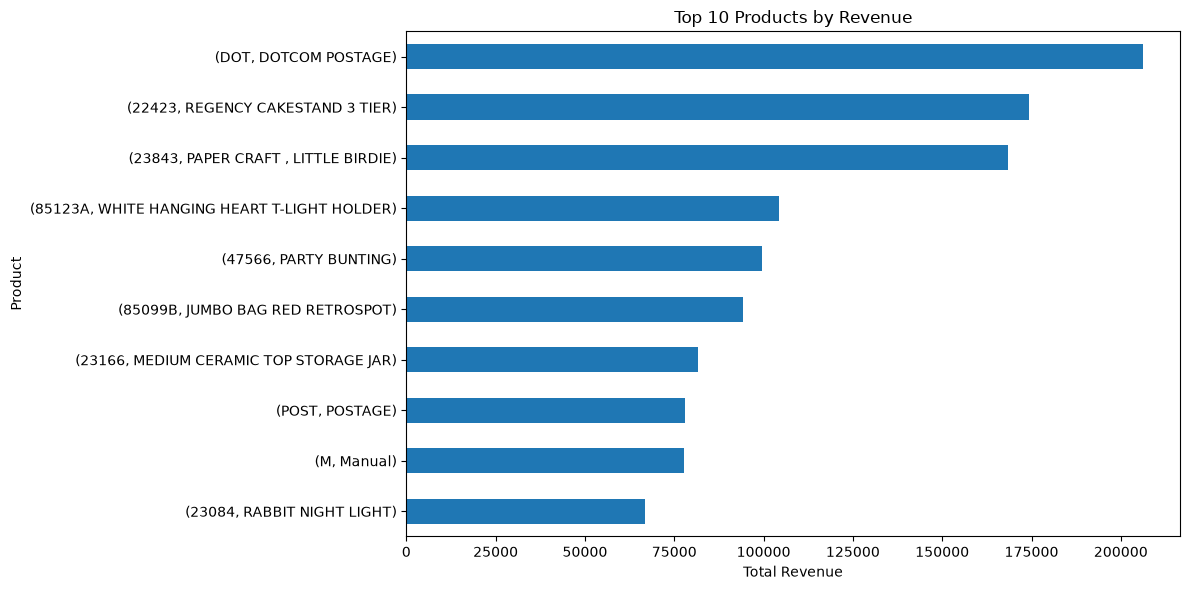

Top products exported: True


In [14]:

# ==========================================
# STEP 13: TOP 10 PRODUCTS BY REVENUE
# ==========================================

# Group sales by product code and description
# Sum the revenue from all transactions for each product
product_revenue = (
    sales_df.groupby(
        ["StockCode", "Description"],
        dropna=False
    )["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 products with the highest total revenue
top_10_products = product_revenue.head(10)

# Convert the results into a table
top_10_table = top_10_products.reset_index(
    name="TotalRevenue"
)

# Display the top 10 products
print("Top 10 Products by Revenue:")
display(top_10_table)

# Create a horizontal bar chart to compare product revenue
plt.figure(figsize=(12, 6))
top_10_products.sort_values().plot(kind="barh")

# Add chart title and labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")

# Improve chart spacing and display it
plt.tight_layout()
plt.show()

# Export the results to a CSV file
top_10_table.to_csv(
    output_dir / "top_10_products.csv",
    index=False
)

print("Top products exported:", 
      (output_dir / "top_10_products.csv").exists())


Top 10 Countries by Revenue:


,Country,TotalRevenue
0,United Kingdom,9001744.094
1,Netherlands,285446.340
2,EIRE,283140.520
3,Germany,228678.400
4,France,209625.370
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,57067.600
8,Belgium,41196.340
9,Sweden,38367.830


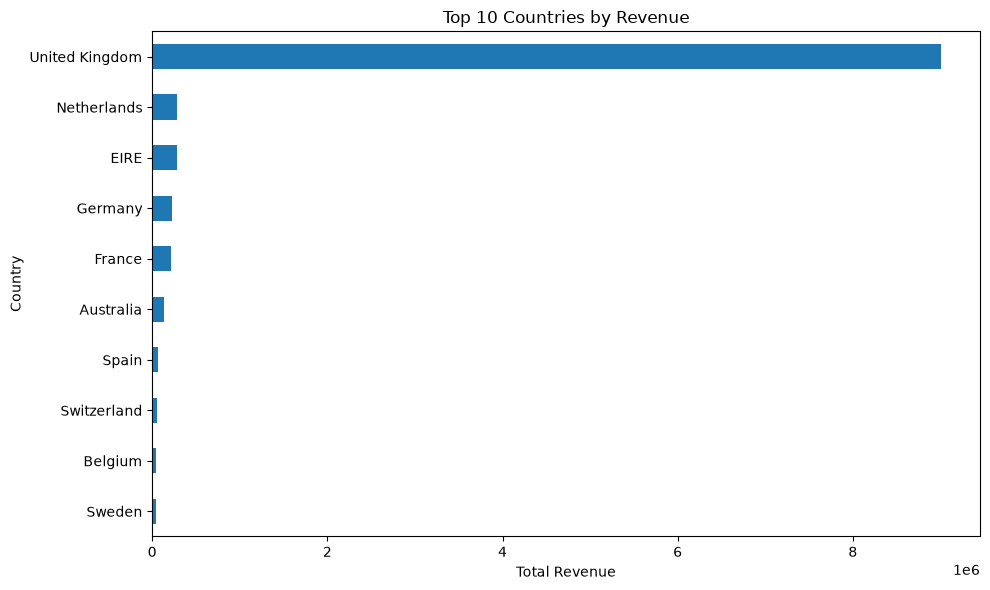

Country revenue exported: True


In [15]:

# ==========================================
# STEP 14: COUNTRY-LEVEL REVENUE ANALYSIS
# ==========================================

# Group sales by country and calculate total revenue
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the 10 highest-revenue countries
top_10_countries = country_revenue.head(10)

# Convert the results into a readable table
country_table = top_10_countries.reset_index(
    name="TotalRevenue"
)

# Display the country rankings
print("Top 10 Countries by Revenue:")
display(country_table)

# Plot country revenue for comparison
plt.figure(figsize=(10, 6))
top_10_countries.sort_values().plot(kind="barh")

# Add a title and axis labels
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

# Export revenue for all countries
country_revenue.rename("Revenue").reset_index().to_csv(
    output_dir / "country_revenue.csv",
    index=False
)

print("Country revenue exported:",
      (output_dir / "country_revenue.csv").exists())


In [16]:

# ==========================================
# STEP 15: PREPARE CUSTOMER-LEVEL DATA
# ==========================================

# Make a copy of the sales data for customer analysis
customer_df = sales_df.copy()

# CustomerID is needed to identify individual customers
# Exclude rows without a customer ID from customer segmentation
customer_df = customer_df.dropna(subset=["CustomerID"])

# Convert CustomerID to an integer for consistent grouping
customer_df["CustomerID"] = (
    customer_df["CustomerID"].astype(int)
)

# Display the number of unique customers
print(
    "Unique customers:",
    customer_df["CustomerID"].nunique()
)

# Display the number of distinct invoices
print(
    "Unique invoices:",
    customer_df["InvoiceNo"].nunique()
)

# Display the first few customer transactions
display(customer_df.head())


Unique customers: 4338
Unique invoices: 18532


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [17]:

# ==========================================
# STEP 16: CALCULATE RFM METRICS
# ==========================================

# Choose one day after the latest invoice date as the analysis date
# This provides a consistent reference point for measuring recency
analysis_date = (
    customer_df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Group transaction data by customer
# Calculate recency, frequency, and monetary value for each customer
rfm = customer_df.groupby("CustomerID").agg(
    # Most recent purchase date for each customer
    LastPurchaseDate=("InvoiceDate", "max"),

    # Count distinct invoices to measure order frequency
    Frequency=("InvoiceNo", "nunique"),

    # Sum revenue to measure customer spending
    Monetary=("Revenue", "sum")
)

# Calculate how many days have passed since the last purchase
rfm["Recency"] = (
    analysis_date - rfm["LastPurchaseDate"]
).dt.days

# Display the RFM results
print("Analysis date:", analysis_date.date())
print("Customer RFM summary:")
display(rfm.head(10))

# Display descriptive statistics for the RFM metrics
print("\nRFM statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


Analysis date: 2011-12-10
Customer RFM summary:


,LastPurchaseDate,Frequency,Monetary,Recency
CustomerID,,,,
12346,2011-01-18 10:01:00,1,77183.60,325
12347,2011-12-07 15:52:00,7,4310.00,2
12348,2011-09-25 13:13:00,4,1797.24,75
12349,2011-11-21 09:51:00,1,1757.55,18
12350,2011-02-02 16:01:00,1,334.40,310
12352,2011-11-03 14:37:00,8,2506.04,36
12353,2011-05-19 17:47:00,1,89.00,204
12354,2011-04-21 13:11:00,1,1079.40,232
12355,2011-05-09 13:49:00,1,459.40,214



RFM statistics:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,306.482500
50%,50.000000,2.000000,668.570000
75%,141.750000,5.000000,1660.597500
max,373.000000,209.000000,280206.020000


In [18]:

# ==========================================
# STEP 17: SCORE AND SEGMENT CUSTOMERS
# ==========================================

# Create five groups for each RFM metric
# Lower recency is better, so reverse its score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Higher frequency indicates more repeat purchases
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Higher monetary value indicates greater customer spending
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Add the three scores to create an overall RFM score
rfm["RFM_Total"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

# Assign simple customer segments based on RFM scores
# These are initial business rules that can be refined later
rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4),

        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] <= 2)
    ],
    [
        "Champions",
        "At Risk",
        "New or Promising"
    ],
    default="Regular Customers"
)

# Display a sample of scored customers
display(rfm.head(10))

# Count the customers in each segment
print("\nCustomers by segment:")
display(
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="CustomerCount")
)


,LastPurchaseDate,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Total,Segment
CustomerID,,,,,,,,,
12346,2011-01-18 10:01:00,1,77183.60,325,1,1,5,7,Regular Customers
12347,2011-12-07 15:52:00,7,4310.00,2,5,5,5,15,Champions
12348,2011-09-25 13:13:00,4,1797.24,75,2,4,4,10,At Risk
12349,2011-11-21 09:51:00,1,1757.55,18,4,1,4,9,New or Promising
12350,2011-02-02 16:01:00,1,334.40,310,1,1,2,4,Regular Customers
12352,2011-11-03 14:37:00,8,2506.04,36,3,5,5,13,Regular Customers
12353,2011-05-19 17:47:00,1,89.00,204,1,1,1,3,Regular Customers
12354,2011-04-21 13:11:00,1,1079.40,232,1,1,4,6,Regular Customers
12355,2011-05-09 13:49:00,1,459.40,214,1,1,2,4,Regular Customers



Customers by segment:


,Segment,CustomerCount
0,Regular Customers,2424
1,Champions,941
2,At Risk,663
3,New or Promising,310


In [19]:

# ==========================================
# STEP 18: EXPORT CUSTOMER SEGMENTATION
# ==========================================

# Save the RFM table so it can be used in Power BI
rfm_export = rfm.reset_index()

# Export customer metrics and segments to CSV
rfm_export.to_csv(
    output_dir / "customer_rfm_segments.csv",
    index=False
)

# Confirm the file was created
print(
    "RFM export successful:",
    (output_dir / "customer_rfm_segments.csv").exists()
)

print("Customers analysed:", len(rfm_export))


RFM export successful: True
Customers analysed: 4338


In [20]:

# ==========================================
# STEP 19: CUSTOMER SEGMENT SUMMARY
# ==========================================

# Count the number of customers in each segment
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        # Count the customers assigned to each segment
        CustomerCount=("Segment", "size"),

        # Calculate the total revenue generated by each segment
        TotalRevenue=("Monetary", "sum"),

        # Calculate the average revenue per customer in each segment
        AverageCustomerRevenue=("Monetary", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

# Calculate the percentage of customers in each segment
segment_summary["CustomerPercentage"] = (
    segment_summary["CustomerCount"]
    / segment_summary["CustomerCount"].sum()
    * 100
)

# Round values to make the table easier to read
segment_summary = segment_summary.round(2)

# Display the segment summary
print("Customer Segment Summary:")
display(segment_summary)

# Export the segment summary for reporting
segment_summary.to_csv(
    output_dir / "customer_segment_summary.csv"
)

print("Segment summary exported successfully!")


Customer Segment Summary:


,CustomerCount,TotalRevenue,AverageCustomerRevenue,CustomerPercentage
Segment,,,,
Champions,941,5741913.58,6101.93,21.69
Regular Customers,2424,2182121.62,900.22,55.88
At Risk,663,827416.57,1247.99,15.28
New or Promising,310,135757.12,437.93,7.15


Segment summary exported successfully!


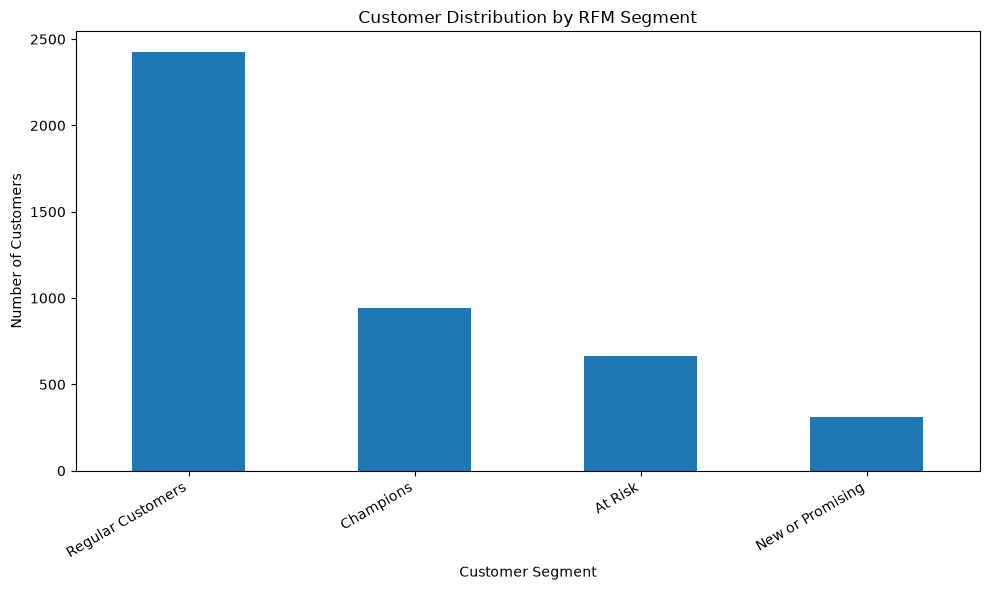

In [21]:

# ==========================================
# STEP 20: CUSTOMER SEGMENT VISUALIZATION
# ==========================================

# Count customers in each segment
segment_counts = rfm["Segment"].value_counts()

# Create a bar chart to compare segment sizes
plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")

# Add a title and axis labels
plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

# Rotate labels for readability
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


In [23]:

# ==========================================
# STEP 21: SUMMARIZE CUSTOMER SEGMENTS
# ==========================================

# Group customers by their assigned RFM segment
# CustomerID is the index, so count rows instead of using CustomerID
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        # Count the number of customers in each segment
        CustomerCount=("Segment", "size"),

        # Calculate total revenue generated by each segment
        TotalRevenue=("Monetary", "sum"),

        # Calculate average spending per customer
        AverageCustomerRevenue=("Monetary", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

# Calculate the percentage of customers in each segment
segment_summary["CustomerPercentage"] = (
    segment_summary["CustomerCount"]
    / segment_summary["CustomerCount"].sum()
    * 100
)

# Round numerical results for easier reading
segment_summary = segment_summary.round(2)

# Display the summary table
print("Customer Segment Summary:")
display(segment_summary)

# Export the summary for reporting and Power BI
segment_summary.to_csv(
    output_dir / "customer_segment_summary.csv"
)

print("Segment summary exported successfully!")


Customer Segment Summary:


,CustomerCount,TotalRevenue,AverageCustomerRevenue,CustomerPercentage
Segment,,,,
Champions,941,5741913.58,6101.93,21.69
Regular Customers,2424,2182121.62,900.22,55.88
At Risk,663,827416.57,1247.99,15.28
New or Promising,310,135757.12,437.93,7.15


Segment summary exported successfully!


In [24]:

# ==========================================
# STEP 22: VERIFY PROJECT OUTPUT FILES
# ==========================================

# List the output files expected from our analysis
expected_files = [
    "retail_sales_cleaned.csv",
    "monthly_revenue.csv",
    "top_10_products.csv",
    "country_revenue.csv",
    "customer_rfm_segments.csv",
    "customer_segment_summary.csv"
]

# Check whether each output file exists
for filename in expected_files:
    file_path = output_dir / filename

    if file_path.exists():
        print(f"{filename}: Found")
    else:
        print(f"{filename}: Missing")


retail_sales_cleaned.csv: Found
monthly_revenue.csv: Found
top_10_products.csv: Found
country_revenue.csv: Found
customer_rfm_segments.csv: Found
customer_segment_summary.csv: Found
